# ClearBank — Análise Financeira com Python

**Desafio final · Pós em IA e Automação**

Notebook que lê o histórico de transações (`transacoes.csv`), valida e limpa os dados, gera métricas mensais, sinaliza transações suspeitas, exibe um relatório formatado e salva o resultado em `relatorio.json`.

| Requisito | Onde está |
|---|---|
| Leitura com `csv.DictReader` + `FileNotFoundError` | `ler_transacoes()` |
| Validação e limpeza | `validar_*()` e `validar_transacao()` |
| Datas com `datetime` | `converter_data()`, `extrair_mes()`, `calcular_periodo()` |
| Métricas mensais e suspeitas | `gerar_relatorio()` |
| JSON | `salvar_json()` |
| Terminal formatado | `exibir_relatorio()` |
| RO1 — pandas | célula de pandas + `analise_pandas.py` |
| RO2 — matplotlib | célula final → `grafico.png` |

> **Ordem de execução:** rode as células de cima para baixo. A *Célula de Execução Principal* só deve ser rodada quando todas as funções estiverem definidas.

## 0. Imports e constantes

In [1]:
import csv
import json
import math
import re
from datetime import date, datetime

LIMITE_SUSPEITO = 10000.00      # acima disso a transação é marcada como suspeita
ARQUIVO_CSV = "transacoes.csv"
ARQUIVO_JSON = "relatorio.json"
FORMATO_DATA = "%Y-%m-%d"
PADRAO_DATA = re.compile(r"^\d{4}-\d{2}-\d{2}$")   # impede formatos tolerados pelo strptime, como 2026-1-5
TIPOS_VALIDOS = ("credito", "debito")

## 1. Arquivo de entrada (`transacoes.csv`)

O arquivo de teste tem **19 registros válidos** em 4 meses (jan–abr/2026), **10 registros inválidos** (valor `abc`, cliente vazio, id não numérico, id vazio, data em formato errado, tipo inválido, valor negativo, valor zero, data impossível e id duplicado) e **2 transações acima de R$ 10.000,00**.

A célula abaixo só cria o arquivo se ele ainda não existir (útil no Colab, onde o arquivo não vem junto com o notebook).

In [2]:
import os

CSV_DE_TESTE = """id,data,cliente_id,tipo,valor,descricao,categoria
1,2026-01-05,CLI001,credito,3500.00,Salário janeiro,salario
2,2026-01-12,CLI002,debito,180.50,Supermercado,compra
3,2026-01-20,CLI001,debito,abc,Erro de sistema,compra
4,2026-01-22,CLI003,credito,2800.00,Salário janeiro,salario
5,2026-01-25,CLI001,debito,450.00,Aluguel parcial,conta
6,2026-02-03,,debito,200.00,Sem cliente,transferencia
7,2026-02-07,CLI002,credito,4200.00,Salário fevereiro,salario
8,2026-02-14,CLI003,credito,15000.00,Transferência suspeita,transferencia
9,2026-02-18,CLI002,debito,320.00,Conta de luz,conta
10,2026-02-20,CLI001,debito,89.90,Restaurante,compra
11,2026-02-27,CLI001,credito,3500.00,Salário fevereiro,salario
12,2026-03-01,CLI001,credito,3500.00,Salário março,salario
13,2026-03-10,CLI003,debito,99.90,Streaming,assinatura
14,2026-03-12,CLI002,debito,1250.75,Material de escritório,compra
15,2026-03-15,CLI002,credito,4200.00,Salário março,salario
16,2026-03-22,CLI004,debito,12500.00,Compra de veículo,compra
17,2026-03-28,CLI004,credito,900.00,Estorno,transferencia
18,2026-04-02,CLI003,credito,2800.00,Salário abril,salario
19,2026-04-09,CLI001,debito,230.40,Farmácia,compra
20,2026-04-15,CLI004,debito,76.00,Transporte,compra
21,2026-04-30,CLI002,debito,540.00,Internet e telefone,conta
abc,2026-04-05,CLI001,debito,50.00,Id não numérico,compra
,2026-04-06,CLI001,debito,50.00,Id vazio,compra
22,05/04/2026,CLI001,debito,50.00,Data em formato errado,compra
23,2026-04-07,CLI001,transferencia,50.00,Tipo inválido,compra
24,2026-04-08,CLI001,debito,-75.00,Valor negativo,compra
25,2026-04-09,CLI002,credito,0,Valor zero,compra
26,2026-13-40,CLI002,debito,10.00,Data impossível,compra
18,2026-04-10,CLI003,credito,2800.00,Id duplicado,salario
"""

if not os.path.exists(ARQUIVO_CSV):
    with open(ARQUIVO_CSV, "w", encoding="utf-8", newline="") as f:
        f.write(CSV_DE_TESTE)
    print(f"{ARQUIVO_CSV} criado com dados de teste.")
else:
    print(f"{ARQUIVO_CSV} já existe — nada a fazer.")

transacoes.csv já existe — nada a fazer.


## 2. Leitura do CSV (`csv.DictReader`)

`try/except` nº 1: arquivo inexistente (`FileNotFoundError`). Retornamos lista vazia para o programa continuar de forma controlada.

In [3]:
def ler_transacoes(caminho):
    """Lê o CSV com csv.DictReader e devolve a lista de linhas brutas (dicionários)."""
    try:
        with open(caminho, encoding="utf-8", newline="") as arquivo:
            return list(csv.DictReader(arquivo))
    except FileNotFoundError:
        print(f"[ERRO] Arquivo '{caminho}' não encontrado.")
        return []


# --- teste rápido ---
brutas = ler_transacoes(ARQUIVO_CSV)
print("Linhas lidas:", len(brutas))
print("Primeira linha:", brutas[0])
print("Arquivo inexistente ->", ler_transacoes("nao_existe.csv"))

Linhas lidas: 29
Primeira linha: {'id': '1', 'data': '2026-01-05', 'cliente_id': 'CLI001', 'tipo': 'credito', 'valor': '3500.00', 'descricao': 'Salário janeiro', 'categoria': 'salario'}
[ERRO] Arquivo 'nao_existe.csv' não encontrado.
Arquivo inexistente -> []


## 3. Validação e limpeza

Uma função por campo (fácil de reutilizar e testar) e uma função que junta tudo para uma linha.
`try/except` nº 2: conversão de `valor` para `float` · `try/except` nº 3: conversão de `data` para `datetime`.
Linhas inválidas são descartadas silenciosamente (retornam `None`).

In [4]:
def validar_id(texto):
    """Retorna o id como int ou None se vazio/não numérico."""
    texto = (texto or "").strip()
    return int(texto) if texto.isdigit() else None


def converter_data(texto):
    """Converte 'AAAA-MM-DD' em datetime. Retorna None se o formato for inválido."""
    texto = (texto or "").strip()
    if not PADRAO_DATA.match(texto):
        return None
    try:
        return datetime.strptime(texto, FORMATO_DATA)
    except ValueError:        # ex.: 2026-13-40
        return None


def validar_valor(texto):
    """Retorna o valor como float (> 0 e finito) ou None."""
    try:
        valor = float((texto or "").strip())
    except ValueError:
        return None
    return valor if math.isfinite(valor) and valor > 0 else None


def validar_transacao(linha, ids_vistos):
    """Valida uma linha. Retorna o registro limpo (dict) ou None se for descartada."""
    id_ = validar_id(linha.get("id"))
    cliente = (linha.get("cliente_id") or "").strip()
    data = converter_data(linha.get("data"))
    tipo = (linha.get("tipo") or "").strip().lower()
    valor = validar_valor(linha.get("valor"))

    if id_ is None or id_ in ids_vistos or not cliente or data is None:
        return None
    if tipo not in TIPOS_VALIDOS or valor is None:
        return None

    ids_vistos.add(id_)
    return {
        "id": id_,
        "data": data,
        "cliente_id": cliente,
        "tipo": tipo,
        "valor": valor,
        "descricao": (linha.get("descricao") or "").strip(),
        "categoria": (linha.get("categoria") or "").strip(),
        "suspeita": valor > LIMITE_SUSPEITO,
    }


def limpar_transacoes(brutas):
    """Valida todas as linhas. Retorna (validas, qtd_invalidas) e imprime o resumo da limpeza."""
    validas, ids_vistos = [], set()
    for linha in brutas:
        registro = validar_transacao(linha, ids_vistos)
        if registro is not None:
            validas.append(registro)
    invalidas = len(brutas) - len(validas)

    print(f"Total de linhas lidas: {len(brutas)}")
    print(f"Linhas válidas: {len(validas)}")
    print(f"Linhas inválidas: {invalidas}")
    return validas, invalidas


# --- testes rápidos ---
print(validar_id("12"), validar_id("abc"), validar_id(""))
print(converter_data("2026-01-05"), converter_data("05/01/2026"), converter_data("2026-13-40"))
print(validar_valor("3500.00"), validar_valor("abc"), validar_valor("-5"), validar_valor("0"))
print()
validas, n_invalidas = limpar_transacoes(brutas)

12 None None
2026-01-05 00:00:00 None None
3500.0 None None None

Total de linhas lidas: 29
Linhas válidas: 19
Linhas inválidas: 10


## 4. Datas com `datetime`

- `strptime` já converte o texto em `datetime` (feito em `converter_data`).
- `strftime("%Y-%m")` extrai o mês.
- A diferença entre a data mais recente e a mais antiga resulta em `timedelta`, de onde tiramos os dias.

In [5]:
def extrair_mes(data):
    """Extrai o mês no formato AAAA-MM de um datetime."""
    return data.strftime("%Y-%m")


def calcular_periodo(transacoes):
    """Retorna (data_mais_antiga, data_mais_recente, dias_entre_elas)."""
    if not transacoes:
        return None, None, 0
    datas = [t["data"] for t in transacoes]
    inicio, fim = min(datas), max(datas)
    return inicio, fim, (fim - inicio).days


# --- teste rápido ---
inicio, fim, dias = calcular_periodo(validas)
print("Mais antiga:", inicio.date(), "| Mais recente:", fim.date(), "| Dias:", dias)
print("Mês da 1ª transação:", extrair_mes(validas[0]["data"]))

Mais antiga: 2026-01-05 | Mais recente: 2026-04-30 | Dias: 115
Mês da 1ª transação: 2026-01


## 5. Agrupamento mensal, métricas e transações suspeitas

In [6]:
def agrupar_por_mes(transacoes):
    """Agrupa as transações num dicionário {'AAAA-MM': [transações]} em ordem cronológica."""
    grupos = {}
    for t in sorted(transacoes, key=lambda x: x["data"]):
        grupos.setdefault(extrair_mes(t["data"]), []).append(t)
    return grupos


def calcular_metricas_mes(lista):
    """Calcula as métricas de uma lista de transações de um mesmo mês."""
    credito = sum(t["valor"] for t in lista if t["tipo"] == "credito")
    debito = sum(t["valor"] for t in lista if t["tipo"] == "debito")
    maior = max(lista, key=lambda t: t["valor"])
    menor = min(lista, key=lambda t: t["valor"])
    return {
        "quantidade": len(lista),
        "total_credito": round(credito, 2),
        "total_debito": round(debito, 2),
        "saldo": round(credito - debito, 2),
        "media": round(sum(t["valor"] for t in lista) / len(lista), 2),
        "maior_valor": maior["valor"],
        "menor_valor": menor["valor"],
    }


def identificar_suspeitas(transacoes):
    """Lista as transações com valor acima de LIMITE_SUSPEITO."""
    return [
        {"id": t["id"], "cliente_id": t["cliente_id"],
         "data": t["data"].strftime(FORMATO_DATA), "valor": t["valor"]}
        for t in transacoes if t["valor"] > LIMITE_SUSPEITO
    ]


def gerar_relatorio(validas, qtd_invalidas):
    """Monta o dicionário final do relatório (mesma estrutura do relatorio.json)."""
    inicio, fim, dias = calcular_periodo(validas)
    resumo = {mes: calcular_metricas_mes(lista) for mes, lista in agrupar_por_mes(validas).items()}
    return {
        "gerado_em": date.today().isoformat(),
        "periodo": {
            "inicio": inicio.strftime(FORMATO_DATA) if inicio else None,
            "fim": fim.strftime(FORMATO_DATA) if fim else None,
            "dias": dias,
        },
        "total_transacoes_validas": len(validas),
        "total_transacoes_invalidas": qtd_invalidas,
        "limite_suspeito": LIMITE_SUSPEITO,
        "resumo_mensal": resumo,
        "transacoes_suspeitas": identificar_suspeitas(validas),
    }


# --- teste rápido ---
teste = gerar_relatorio(validas, n_invalidas)
print(json.dumps(teste["resumo_mensal"]["2026-01"], indent=2, ensure_ascii=False))
print("Suspeitas:", teste["transacoes_suspeitas"])

{
  "quantidade": 4,
  "total_credito": 6300.0,
  "total_debito": 630.5,
  "saldo": 5669.5,
  "media": 1732.62,
  "maior_valor": 3500.0,
  "menor_valor": 180.5
}
Suspeitas: [{'id': 8, 'cliente_id': 'CLI003', 'data': '2026-02-14', 'valor': 15000.0}, {'id': 16, 'cliente_id': 'CLI004', 'data': '2026-03-22', 'valor': 12500.0}]


## 6. Exportação em JSON

In [7]:
def salvar_json(relatorio, caminho):
    """Salva o relatório em JSON (UTF-8, indentado, com acentos)."""
    try:
        with open(caminho, "w", encoding="utf-8") as arquivo:
            json.dump(relatorio, arquivo, ensure_ascii=False, indent=2)
        print(f"Relatório salvo em '{caminho}'.")
        return True
    except OSError as erro:
        print(f"[ERRO] Não foi possível salvar '{caminho}': {erro}")
        return False


# --- teste rápido ---
salvar_json(teste, "teste_relatorio.json")
with open("teste_relatorio.json", encoding="utf-8") as f:
    print("Chaves do JSON:", list(json.load(f).keys()))
os.remove("teste_relatorio.json")

Relatório salvo em 'teste_relatorio.json'.
Chaves do JSON: ['gerado_em', 'periodo', 'total_transacoes_validas', 'total_transacoes_invalidas', 'limite_suspeito', 'resumo_mensal', 'transacoes_suspeitas']


## 7. Exibição formatada no terminal

In [8]:
def formatar_moeda(valor):
    """Formata no padrão brasileiro: R$ 1.234,56."""
    texto = f"{valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
    return f"R$ {texto}"


def exibir_resumo_geral(rel):
    p = rel["periodo"]
    print("=" * 40)
    print("      CLEARBANK — ANÁLISE FINANCEIRA")
    print("=" * 40)
    print(f"Gerado em: {rel['gerado_em']}")
    print(f"Período analisado: {p['inicio']} → {p['fim']} ({p['dias']} dias)")
    print(f"Transações válidas:   {rel['total_transacoes_validas']}")
    print(f"Transações inválidas: {rel['total_transacoes_invalidas']}")


def exibir_mes(mes, m):
    print(f"\nMês: {mes}")
    print(f"  Transações:    {m['quantidade']}")
    print(f"  Total crédito: {formatar_moeda(m['total_credito'])}")
    print(f"  Total débito:  {formatar_moeda(m['total_debito'])}")
    print(f"  Saldo:         {formatar_moeda(m['saldo'])}")
    print(f"  Média:         {formatar_moeda(m['media'])}")
    print(f"  Maior valor:   {formatar_moeda(m['maior_valor'])}")
    print(f"  Menor valor:   {formatar_moeda(m['menor_valor'])}")


def exibir_suspeitas(suspeitas):
    print("\n" + "=" * 40)
    print("===== TRANSAÇÕES SUSPEITAS =====")
    print("=" * 40)
    if not suspeitas:
        print("Nenhuma transação suspeita encontrada.")
    for s in suspeitas:
        print(f"ID: {s['id']} | Cliente: {s['cliente_id']} | Data: {s['data']} | Valor: {formatar_moeda(s['valor'])}")


def exibir_relatorio(rel):
    """Imprime o relatório completo: resumo geral, meses e suspeitas."""
    exibir_resumo_geral(rel)
    print("\n===== RELATÓRIO MENSAL =====")
    for mes, metricas in rel["resumo_mensal"].items():
        exibir_mes(mes, metricas)
    exibir_suspeitas(rel["transacoes_suspeitas"])


# --- testes rápidos ---
print(formatar_moeda(3500), formatar_moeda(180.5), formatar_moeda(1234567.891))
exibir_suspeitas([])

R$ 3.500,00 R$ 180,50 R$ 1.234.567,89

===== TRANSAÇÕES SUSPEITAS =====
Nenhuma transação suspeita encontrada.


## 8. ▶ Célula de Execução Principal

Chama todas as funções em sequência: **ler → validar → gerar relatório → salvar JSON → exibir**.

In [9]:
def main():
    brutas = ler_transacoes(ARQUIVO_CSV)
    if not brutas:
        print("Nenhum dado para processar.")
        return None

    print("===== RESUMO DA LIMPEZA =====")
    validas, invalidas = limpar_transacoes(brutas)
    print()

    relatorio = gerar_relatorio(validas, invalidas)
    salvar_json(relatorio, ARQUIVO_JSON)
    print()
    exibir_relatorio(relatorio)
    return relatorio


resultado = main()

===== RESUMO DA LIMPEZA =====
Total de linhas lidas: 29
Linhas válidas: 19
Linhas inválidas: 10

Relatório salvo em 'relatorio.json'.

      CLEARBANK — ANÁLISE FINANCEIRA
Gerado em: 2026-11-10
Período analisado: 2026-01-05 → 2026-04-30 (115 dias)
Transações válidas:   19
Transações inválidas: 10

===== RELATÓRIO MENSAL =====

Mês: 2026-01
  Transações:    4
  Total crédito: R$ 6.300,00
  Total débito:  R$ 630,50
  Saldo:         R$ 5.669,50
  Média:         R$ 1.732,62
  Maior valor:   R$ 3.500,00
  Menor valor:   R$ 180,50

Mês: 2026-02
  Transações:    5
  Total crédito: R$ 22.700,00
  Total débito:  R$ 409,90
  Saldo:         R$ 22.290,10
  Média:         R$ 4.621,98
  Maior valor:   R$ 15.000,00
  Menor valor:   R$ 89,90

Mês: 2026-03
  Transações:    6
  Total crédito: R$ 8.600,00
  Total débito:  R$ 13.850,65
  Saldo:         R$ -5.250,65
  Média:         R$ 3.741,78
  Maior valor:   R$ 12.500,00
  Menor valor:   R$ 99,90

Mês: 2026-04
  Transações:    4
  Total crédito: R$ 2.80

## Opcional RO1 — Análise com pandas

Mesma leitura/agrupamento usando `pd.read_csv()` e `groupby`, comparando com a solução nativa. A versão como script separado está em `analise_pandas.py`.

In [10]:
import pandas as pd


def carregar_pandas(caminho=ARQUIVO_CSV):
    """Lê o CSV com pd.read_csv e devolve (df_valido, total_lidas, total_invalidas)."""
    df = pd.read_csv(caminho, dtype=str)
    total = len(df)

    df["id"] = pd.to_numeric(df["id"], errors="coerce")
    df["valor"] = pd.to_numeric(df["valor"], errors="coerce")
    data_ok = df["data"].fillna("").str.match(r"^\d{4}-\d{2}-\d{2}$")
    df["data"] = pd.to_datetime(df["data"].where(data_ok), format="%Y-%m-%d", errors="coerce")
    df["cliente_id"] = df["cliente_id"].fillna("").str.strip()
    df["tipo"] = df["tipo"].fillna("").str.strip().str.lower()

    mascara = (
        df["id"].notna()
        & (df["id"] % 1 == 0)
        & (df["cliente_id"] != "")
        & df["data"].notna()
        & df["tipo"].isin(["credito", "debito"])
        & (df["valor"] > 0)
        & df["valor"].map(lambda v: math.isfinite(v) if pd.notna(v) else False)
    )
    df = df[mascara].drop_duplicates(subset="id", keep="first").copy()
    df["id"] = df["id"].astype(int)
    return df, total, total - len(df)


def agrupar_pandas(df):
    """Agrupa por mês (AAAA-MM) com groupby e calcula as métricas."""
    df = df.assign(mes=df["data"].dt.strftime("%Y-%m"))
    stats = df.groupby("mes")["valor"].agg(["count", "mean", "max", "min"])
    credito = df[df["tipo"] == "credito"].groupby("mes")["valor"].sum().rename("credito")
    debito = df[df["tipo"] == "debito"].groupby("mes")["valor"].sum().rename("debito")
    resumo = stats.join(credito).join(debito).fillna(0.0)
    resumo["saldo"] = resumo["credito"] - resumo["debito"]
    return resumo


def comparar(resumo_nativo, resumo_pandas):
    """Compara, mês a mês, os valores da solução nativa com os do pandas."""
    if set(resumo_nativo) != set(resumo_pandas.index):
        return False
    pares = {
        "quantidade": "count",
        "total_credito": "credito",
        "total_debito": "debito",
        "saldo": "saldo",
        "media": "mean",
        "maior_valor": "max",
        "menor_valor": "min",
    }
    for mes, metricas in resumo_nativo.items():
        for chave_nativa, coluna in pares.items():
            if not math.isclose(metricas[chave_nativa], float(resumo_pandas.loc[mes, coluna]), abs_tol=0.01):
                return False
    return True


df_pandas, lidas_pd, invalidas_pd = carregar_pandas(ARQUIVO_CSV)
resumo_pandas = agrupar_pandas(df_pandas)

print(f"Linhas lidas: {lidas_pd} | válidas: {len(df_pandas)} | inválidas: {invalidas_pd}\n")
print(resumo_pandas.round(2).to_string())
print("\nResultados idênticos à solução nativa:", comparar(resultado["resumo_mensal"], resumo_pandas))

Linhas lidas: 29 | válidas: 19 | inválidas: 10

         count     mean      max    min  credito    debito     saldo
mes                                                                 
2026-01      4  1732.62   3500.0  180.5   6300.0    630.50   5669.50
2026-02      5  4621.98  15000.0   89.9  22700.0    409.90  22290.10
2026-03      6  3741.78  12500.0   99.9   8600.0  13850.65  -5250.65
2026-04      4   911.60   2800.0   76.0   2800.0    846.40   1953.60

Resultados idênticos à solução nativa: True


## Opcional RO2 — Visualização com matplotlib

Opção C: barras empilhadas com crédito e débito por mês, com o saldo mensal em linha. Salvo em `grafico.png`.

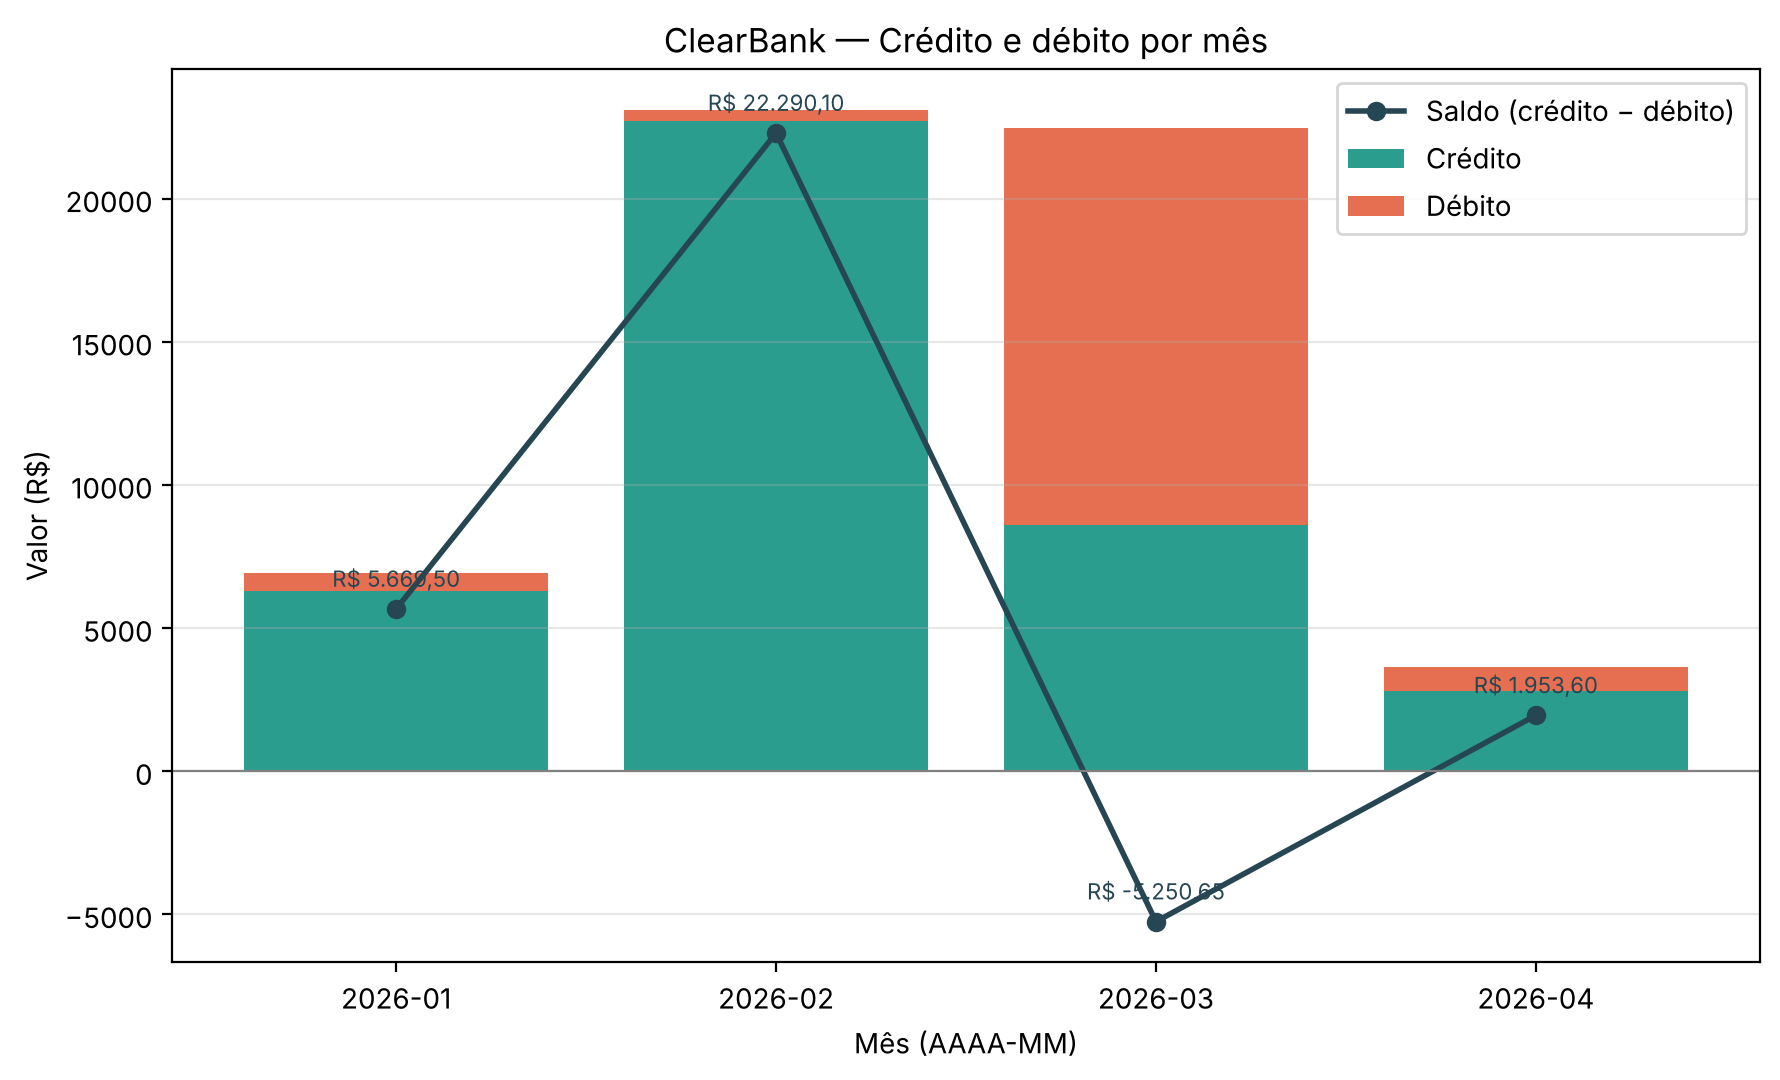

Gráfico salvo em grafico.png


In [11]:
import matplotlib.pyplot as plt

meses = list(resultado["resumo_mensal"])
creditos = [resultado["resumo_mensal"][m]["total_credito"] for m in meses]
debitos = [resultado["resumo_mensal"][m]["total_debito"] for m in meses]
saldos = [resultado["resumo_mensal"][m]["saldo"] for m in meses]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.bar(meses, creditos, label="Crédito", color="#2a9d8f")
ax.bar(meses, debitos, bottom=creditos, label="Débito", color="#e76f51")
ax.plot(meses, saldos, marker="o", color="#264653", linewidth=2, label="Saldo (crédito − débito)")

for mes, saldo in zip(meses, saldos):
    ax.annotate(formatar_moeda(saldo), (mes, saldo), textcoords="offset points",
                xytext=(0, 8), ha="center", fontsize=8, color="#264653")

ax.set_title("ClearBank — Crédito e débito por mês")
ax.set_xlabel("Mês (AAAA-MM)")
ax.set_ylabel("Valor (R$)")
ax.axhline(0, color="gray", linewidth=0.8)
ax.legend()
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig("grafico.png", dpi=150)
plt.show()
print("Gráfico salvo em grafico.png")